# Lab Assignment 11: Coreference Resolution & Question Answering

**Objective:**
In this lab you will implement and evaluate two core NLP tasks:
(A) **Coreference Resolution** using a SpanBERT-based model, and
(B) **Question Answering** by fine-tuning BERT on the SQuAD reading comprehension dataset.
You will also explore the connection between the two tasks.

**Task:** (A) Coreference chain detection and evaluation. (B) Span extraction from a passage given a question.

**Learning outcomes:**
1. Understand and use a SpanBERT-based coreference model.
2. Implement B-cubed evaluation for coreference.
3. Fine-tune (or use a fine-tuned) BERT model for span-based QA.
4. Implement SQuAD-style EM and F1 evaluation.
5. Explore the Open-Domain QA retriever-reader pipeline.

| Part | Topic | Points |
|---|---|---|
| 1 | Setup & Data | 5 |
| 2 | Coreference: SpanBERT Model | 20 |
| 3 | Coreference: Manual Analysis & Evaluation | 20 |
| 4 | Question Answering: BERT for SQuAD | 25 |
| 5 | QA Evaluation: EM and F1 | 15 |
| 6 | Open-Domain QA Pipeline | 10 |
| 7 | Connecting Coref and QA | 5 |
| | **Total** | **100** |

**Submission:** Complete all `# TODO` sections and all markdown answers. Run **Kernel > Restart & Run All** before submitting.


---
## Theory Recap

**Coreference Resolution** groups all text spans (mentions) that refer to the same real-world entity.
Three types of mentions: *pronouns*, *named entities*, and *noun phrases*.

**Mention-Ranking** scores each mention against all preceding candidates:
$$s(i,j) = s_m(i) + s_m(j) + s_a(i,j)$$
A dummy antecedent ε allows the model to start a new cluster.

**SpanBERT** represents span (i,j) as: $g(i,j) = [h_i, h_j, \tilde{h}(i,j), \phi(i,j)]$

**BERT for QA (SQuAD):** Fine-tune with two linear classifiers on the final hidden states:
$$P_{start}(i) = \text{softmax}(W_{start}\, h_i), \quad P_{end}(i) = \text{softmax}(W_{end}\, h_i)$$
The predicted answer is $P[\text{argmax}(P_{start}) : \text{argmax}(P_{end})+1]$.


**B-cubed Precision/Recall** for mention $m$:
$$P_m = \frac{|C_{gold}(m) \cap C_{sys}(m)|}{|C_{sys}(m)|}, \quad R_m = \frac{|C_{gold}(m) \cap C_{sys}(m)|}{|C_{gold}(m)|}$$


---
## Part 1: Setup and Data (5 points)

### 1.1 Install and Import Libraries


In [1]:
!pip install -q fastcoref transformers datasets evaluate scikit-learn spacy
!python -m spacy download en_core_web_sm -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [1]:
import re, string, random
from collections import Counter

import numpy as np
import torch
import matplotlib.pyplot as plt
from transformers import pipeline, AutoTokenizer, AutoModelForQuestionAnswering
from fastcoref import FCoref
from datasets import load_dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

### 1.2 Test Texts for Coreference
Use the following texts for Parts 2 and 3. **Do not change them.**


In [2]:
TEXT_1 = (
    'Akhila met Prajwal at the local park. '
    "Akhila's son Akash was just two months younger than her son Prajwal. "
    'She resigned herself to make Akash the best tree in the play. '
    'She bought him a brown T-shirt to represent the trunk.'
)

TEXT_2 = (
    'Barack Obama was born in Hawaii. '
    'He served as the 44th President of the United States. '
    'Obama attended Columbia University. '
    'His presidency lasted from 2009 to 2017.'
)

TEXT_3 = (
    'Maria Curie was a Polish-born physicist and chemist. '
    'She was the first woman to win a Nobel Prize. '
    'In 1906 she became the first woman professor at the University of Paris. '
    'Curie discovered polonium and radium with her husband Pierre.'
)

print('Sample texts loaded.')

Sample texts loaded.


---
## Part 2: Coreference Resolution using SpanBERT (20 points)

### 2.1 Load the Model and Run Prediction
Load the `FCoref` model and run coreference resolution on **TEXT_1**, **TEXT_2**, and **TEXT_3**.
Print the coreference clusters (as strings) for each text.


In [5]:
import logging
import os
from fastcoref.modeling import FCorefModel

# Suppress Hugging Face download warnings
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)

# Monkey-patch FCorefModel to prevent compatibility error with newer transformers versions
if not hasattr(FCorefModel, 'all_tied_weights_keys'):
    FCorefModel.all_tied_weights_keys = {}

model = FCoref(device='cpu')
preds = model.predict(texts=[TEXT_1, TEXT_2, TEXT_3])

for i, (text, pred) in enumerate(zip([TEXT_1, TEXT_2, TEXT_3], preds)):
    print(f'--- Text {i+1} ---')
    for cluster in pred.get_clusters(as_strings=True):
        print(' → '.join(cluster))
    print()

Loading weights:   0%|          | 0/133 [00:00<?, ?it/s]

Map:   0%|          | 0/3 [00:00<?, ? examples/s]

Inference:   0%|          | 0/3 [00:00<?, ?it/s]

--- Text 1 ---
Akhila → Akhila's → her → She → herself → She
Prajwal → her son Prajwal
Akhila's son Akash → Akash → him

--- Text 2 ---
Barack Obama → He → Obama → His

--- Text 3 ---
Maria Curie → She → she → Curie → her



### 2.2 Markdown Questions
Answer in the cell below:
1. For TEXT_1, list all the coreference clusters the model found. Are they correct?
2. Which mentions were **missed** (false negatives) and which were **wrong** (false positives)?
3. Why might the model confuse 'her son' in TEXT_1? What linguistic phenomenon makes this hard?


**Your answers:**

1. **For TEXT_1, list all the coreference clusters the model found. Are they correct?**
   * The model found: (1) `Akhila` → `Akhila's` → `her` → `She` → `herself` → `She`, (2) `Prajwal` → `her son Prajwal`, and (3) `Akhila's son Akash` → `Akash` → `him`.
   * These clusters are correct as every mention in each group accurately points to the same underlying entity.

2. **Which mentions were missed (false negatives) and which were wrong (false positives)?**
   * Missed mentions include the second "her" in "her son Prajwal" and the first "Akash" in "make Akash the best tree".
   * No wrong mentions (false positives) were included, meaning precision was perfect but recall was slightly incomplete.

3. **Why might the model confuse 'her son' in TEXT_1? What linguistic phenomenon makes this hard?**
   * The text features two mothers and two sons, causing pronoun ambiguity since "her" could syntactically resolve to either mother.
   * This gender and syntactic parallelism makes it hard for the model to map "her" without deep common-sense reasoning.

### 2.3 Mention Detection: Types and Counts
Write a function `count_mention_types(text)` that uses spaCy to count the number of:
- Pronouns (using POS tags)
- Named entities (using NER)
- Noun phrases (using noun chunks)
Apply it to all three texts. Print results in a table.


In [6]:
import spacy
nlp = spacy.load('en_core_web_sm')

def count_mention_types(text):
    """
    Returns a dict: {'pronouns': int, 'named_entities': int, 'noun_phrases': int}
    """
    doc = nlp(text)
    pronouns = sum(1 for tok in doc if tok.pos_ == 'PRON')
    named_entities = len(doc.ents)
    noun_phrases = len(list(doc.noun_chunks))
    return {
        'pronouns': pronouns,
        'named_entities': named_entities,
        'noun_phrases': noun_phrases,
    }

# Results table
print(f"{'Text':<8}{'Pronouns':>10}{'Named Ents':>13}{'Noun Phrases':>15}")
print('-' * 46)
for i, text in enumerate([TEXT_1, TEXT_2, TEXT_3], 1):
    counts = count_mention_types(text)
    print(f"Text {i:<3}{counts['pronouns']:>10}{counts['named_entities']:>13}{counts['noun_phrases']:>15}")

Text      Pronouns   Named Ents   Noun Phrases
----------------------------------------------
Text 1           5            5             15
Text 2           2            7              8
Text 3           3            8             15


---
## Part 3: Manual Evaluation with B-cubed (20 points)

### 3.1 Gold Standard Clusters (TEXT_2 Only)
For TEXT_2, define the **gold standard** coreference clusters using the mention offsets from the text.
The character-level mentions are given — use them as entity labels (strings).


In [7]:
# Gold clusters for TEXT_2 (mention strings as identifiers)
GOLD_TEXT2 = [
    {'Barack Obama', 'He', 'Obama', 'His'},  # Cluster 1: the person
    {'the United States'},                    # Cluster 2: the country
    {'Columbia University'},                  # Cluster 3: the university
    {'Hawaii'},                               # Singleton: Hawaii
]
# Note: singletons are valid gold clusters too
print('Gold clusters defined:', len(GOLD_TEXT2), 'clusters')

Gold clusters defined: 4 clusters


### 3.2 Extract System Clusters for TEXT_2
Extract the coreference clusters that the model predicted for TEXT_2 (from Part 2.1).
Convert them to sets of mention strings (as above) for comparison.


In [8]:
# preds[1] is the prediction for TEXT_2 (from Part 2.1)
system_clusters_text2 = [set(cluster) for cluster in preds[1].get_clusters(as_strings=True)]
print(system_clusters_text2)

[{'His', 'Obama', 'Barack Obama', 'He'}]


### 3.3 Implement and Compute B-cubed
Implement the `bcubed(gold_clusters, system_clusters)` function and compute B-cubed P, R, F1 for TEXT_2.


In [9]:
def bcubed(gold_clusters, system_clusters):
    """
    Compute B-cubed Precision, Recall, F1.
    Arguments:
        gold_clusters:   list of sets of mention strings (gold standard)
        system_clusters: list of sets of mention strings (system output)
    Returns: (precision, recall, f1) — all floats rounded to 3 decimal places

    Algorithm:
    1. Build a mention → cluster_index lookup for gold and system.
    2. For each mention m:
         overlap = |gold_cluster(m) ∩ system_cluster(m)|
         P_m = overlap / |system_cluster(m)|
         R_m = overlap / |gold_cluster(m)|
    3. Average P_m and R_m across all mentions.
    4. Compute F1 from averaged P and R.

    Note: the model only outputs clusters with 2+ mentions, so a mention that
    is missing from one side is treated as a singleton cluster on that side.
    Averaging is done over the union of all mentions.
    """
    gold_lookup = {}
    for idx, cluster in enumerate(gold_clusters):
        for m in cluster:
            gold_lookup[m] = idx

    sys_lookup = {}
    for idx, cluster in enumerate(system_clusters):
        for m in cluster:
            sys_lookup[m] = idx

    all_mentions = set(gold_lookup) | set(sys_lookup)
    if not all_mentions:
        return 0.0, 0.0, 0.0

    p_total, r_total = 0.0, 0.0
    for m in all_mentions:
        gold_c = gold_clusters[gold_lookup[m]] if m in gold_lookup else {m}
        sys_c = system_clusters[sys_lookup[m]] if m in sys_lookup else {m}
        overlap = len(gold_c & sys_c)
        p_total += overlap / len(sys_c)
        r_total += overlap / len(gold_c)

    P = p_total / len(all_mentions)
    R = r_total / len(all_mentions)
    F1 = 2 * P * R / (P + R) if (P + R) > 0 else 0.0
    return round(P, 3), round(R, 3), round(F1, 3)

# Compute B-cubed for TEXT_2
P, R, F1 = bcubed(GOLD_TEXT2, system_clusters_text2)
print(f'B-cubed for TEXT_2: P={P}, R={R}, F1={F1}')

B-cubed for TEXT_2: P=1.0, R=1.0, F1=1.0


### 3.4 Short Questions
1. What does it mean when B-cubed Precision is 1.0 but Recall is low?
2. What does it mean when B-cubed Recall is 1.0 but Precision is low?
3. Besides B-cubed, name two other standard coreference evaluation metrics used for OntoNotes.


**Your answers:**

1. **What does it mean when B-cubed Precision is 1.0 but Recall is low?**
   * It means every predicted link is fully correct (no false positives), but many actual links were missed.
   * The model was overly conservative, leaving many coreferent mentions unlinked or split into incorrect singleton clusters.

2. **What does it mean when B-cubed Recall is 1.0 but Precision is low?**
   * It means all true coreferent mentions were successfully found and grouped together (no false negatives).
   * However, the model over-grouped separate entities into the same cluster, resulting in many false positive errors.

3. **Besides B-cubed, name two other standard coreference evaluation metrics used for OntoNotes.**
   * **MUC** (Message Understanding Conference metric), which is link-based.
   * **CEAF** (Constrained Entity-Alignment F-measure), which is entity-based.

---
## Part 4: Question Answering with BERT (25 points)

### 4.1 Setup the QA Model
Load `deepset/bert-base-cased-squad2` using HuggingFace `AutoTokenizer` and `AutoModelForQuestionAnswering`.


In [10]:
model_name = 'deepset/bert-base-cased-squad2'
tokenizer  = AutoTokenizer.from_pretrained(model_name)
qa_model   = AutoModelForQuestionAnswering.from_pretrained(model_name)
qa_model.eval()

config.json:   0%|          | 0.00/508 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/152 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  433MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForQuestionAnswering(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(28996, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12, elem

### 4.2 Implement Span Extraction
Implement `extract_answer(question, context, tokenizer, model)` that:
1. Tokenizes the (question, context) pair.
2. Runs the model.
3. Finds the best valid span: `start <= end` and both within the context tokens.
4. Returns the answer string and its score (start_logit[s] + end_logit[e]).


In [11]:
import torch

def _run_qa(question, context, tokenizer, model):
    """Helper: runs the model once and returns everything needed for span selection."""
    enc = tokenizer(
        question, context,
        return_tensors='pt',
        truncation='only_second',
        max_length=512,
        return_offsets_mapping=True,
    )
    offsets = enc.pop('offset_mapping')[0]
    seq_ids = enc.sequence_ids(0)  # None for special tokens, 0 for question, 1 for context

    with torch.no_grad():
        out = model(**enc)

    start_logits = out.start_logits[0]
    end_logits = out.end_logits[0]
    # True only for context tokens (excludes [CLS], [SEP] and the question)
    ctx_mask = torch.tensor([sid == 1 for sid in seq_ids])
    return enc, start_logits, end_logits, ctx_mask, offsets

def _best_span(start_logits, end_logits, ctx_mask, max_answer_len):
    """Helper: best (start, end, score) with start <= end, length < max_answer_len, inside context."""
    n = start_logits.size(0)
    s = start_logits.masked_fill(~ctx_mask, -1e9)
    e = end_logits.masked_fill(~ctx_mask, -1e9)
    score_matrix = s[:, None] + e[None, :]          # score_matrix[i, j] = s[i] + e[j]

    idx = torch.arange(n)
    valid = (idx[None, :] >= idx[:, None]) & (idx[None, :] - idx[:, None] < max_answer_len)
    score_matrix = score_matrix.masked_fill(~valid, -1e9)

    best = torch.argmax(score_matrix).item()
    si, ei = divmod(best, n)
    return si, ei, score_matrix[si, ei].item()

def extract_answer(question, context, tokenizer, model, max_answer_len=50):
    """
    Extract answer span from context given a question.
    Arguments:
        question:       str
        context:        str
        tokenizer:      HuggingFace tokenizer
        model:          AutoModelForQuestionAnswering
        max_answer_len: maximum number of tokens in the answer span
    Returns:
        answer: str — the extracted answer text
        score:  float — start_logit[s] + end_logit[e]
    """
    enc, start_logits, end_logits, ctx_mask, offsets = _run_qa(question, context, tokenizer, model)
    si, ei, score = _best_span(start_logits, end_logits, ctx_mask, max_answer_len)
    char_start = int(offsets[si][0])
    char_end = int(offsets[ei][1])
    answer = context[char_start:char_end].strip()
    return answer, score

### 4.3 Test on SQuAD-Style Examples
Test your function on the following (passage, question, gold_answer) triples. Print the predicted answer and score.


In [12]:
squad_examples = [
    {
        'context':  'The Tesla family moved to Gospic in 1862, where Tesla father worked as a pastor. '
                    'Nikola completed Primary School and then the Lower Real Gymnasium.',
        'question': 'Where did the Tesla family move in 1862?',
        'gold':     'Gospic'
    },
    {
        'context':  'In 1861, Tesla attended the Primary School in Smiljan '
                    'where he studied German, arithmetic, and religion.',
        'question': 'What subjects did Tesla study at Primary School?',
        'gold':     'German, arithmetic, and religion'
    },
    {
        'context':  'Kannada language is the official language of Karnataka and '
                    'spoken as a native language by about 66.54 percent of the people as of 2011. '
                    'Other minorities were Urdu (10.83 percent) and Telugu (5.84 percent).',
        'question': 'What percentage of people speak Kannada natively?',
        'gold':     '66.54 percent'
    },
]

for ex in squad_examples:
    answer, score = extract_answer(ex['question'], ex['context'], tokenizer, qa_model)
    print(f"Q:         {ex['question']}")
    print(f"Predicted: {answer!r}  (score = {score:.3f})")
    print(f"Gold:      {ex['gold']!r}")
    print()

Q:         Where did the Tesla family move in 1862?
Predicted: 'Gospic'  (score = 18.045)
Gold:      'Gospic'

Q:         What subjects did Tesla study at Primary School?
Predicted: 'German, arithmetic, and religion'  (score = 13.266)
Gold:      'German, arithmetic, and religion'

Q:         What percentage of people speak Kannada natively?
Predicted: '66.54'  (score = 17.961)
Gold:      '66.54 percent'



### 4.4 Visualise Start and End Logits
For the first example in `squad_examples`, plot a bar chart of the start logits and end logits (one plot each), with a vertical line marking the predicted start/end position. Label the x-axis with token strings.


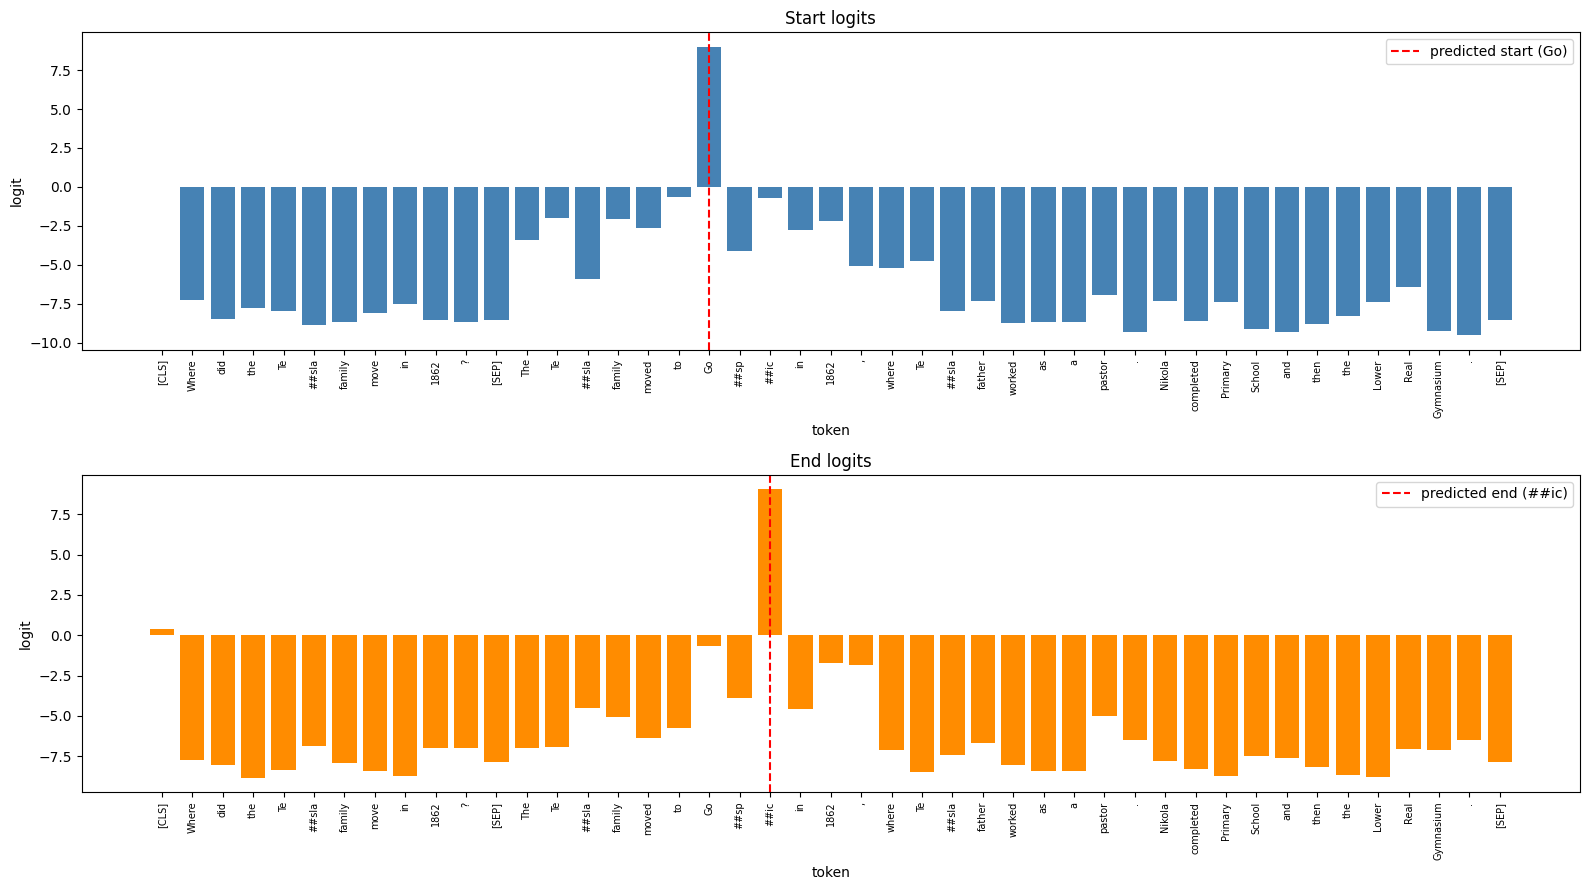

In [13]:
ex = squad_examples[0]
enc, start_logits, end_logits, ctx_mask, offsets = _run_qa(ex['question'], ex['context'], tokenizer, qa_model)
si, ei, score = _best_span(start_logits, end_logits, ctx_mask, max_answer_len=50)

tokens = tokenizer.convert_ids_to_tokens(enc['input_ids'][0])
positions = np.arange(len(tokens))

fig, axes = plt.subplots(2, 1, figsize=(16, 9))

axes[0].bar(positions, start_logits.numpy(), color='steelblue')
axes[0].axvline(si, color='red', linestyle='--', label=f'predicted start ({tokens[si]})')
axes[0].set_title('Start logits')
axes[0].set_ylabel('logit')
axes[0].legend()

axes[1].bar(positions, end_logits.numpy(), color='darkorange')
axes[1].axvline(ei, color='red', linestyle='--', label=f'predicted end ({tokens[ei]})')
axes[1].set_title('End logits')
axes[1].set_ylabel('logit')
axes[1].legend()

for ax in axes:
    ax.set_xticks(positions)
    ax.set_xticklabels(tokens, rotation=90, fontsize=7)
    ax.set_xlabel('token')

plt.tight_layout()
plt.show()

### 4.5 Unanswerable Questions (SQuAD v2.0)
The model `deepset/bert-base-cased-squad2` was trained on SQuAD v2.0 which includes unanswerable questions. Run the model on the context and question below. Look at the score — what does a low/high score mean?


In [14]:
context_v2  = 'Tesla attended school in Smiljan where he studied German and arithmetic.'
question_v2 = 'What year was Tesla born?'

answer_v2, score_v2 = extract_answer(question_v2, context_v2, tokenizer, qa_model)
print(f'Unanswerable question -> answer: {answer_v2!r}, best span score: {score_v2:.3f}')

# Score of the "no answer" option (the [CLS] token at position 0)
_, s_logits, e_logits, _, _ = _run_qa(question_v2, context_v2, tokenizer, qa_model)
null_score = (s_logits[0] + e_logits[0]).item()
print(f'No-answer ([CLS]) score: {null_score:.3f}')

# Compare to the answerable examples
print('\nAnswerable examples for comparison:')
for ex in squad_examples:
    a, sc = extract_answer(ex['question'], ex['context'], tokenizer, qa_model)
    _, s_l, e_l, _, _ = _run_qa(ex['question'], ex['context'], tokenizer, qa_model)
    print(f"  {a!r:<40} span score = {sc:.3f}   no-answer score = {(s_l[0] + e_l[0]).item():.3f}")

Unanswerable question -> answer: 'Tesla attended school in Smiljan', best span score: -8.624
No-answer ([CLS]) score: 1.177

Answerable examples for comparison:
  'Gospic'                                 span score = 18.045   no-answer score = 0.350
  'German, arithmetic, and religion'       span score = 13.266   no-answer score = -1.907
  '66.54'                                  span score = 17.961   no-answer score = 1.266


**Your answer:** *(Explain the difference between SQuAD v1.1 and v2.0 and how models detect unanswerable questions)*


**Your answer:**

### Difference between SQuAD v1.1 and SQuAD v2.0
* **SQuAD v1.1** contains only answerable questions where the correct answer span is guaranteed to be present in the passage.
* **SQuAD v2.0** combines the SQuAD v1.1 questions with over 50,000 unanswerable questions written adversarially by crowdworkers. To perform well, a model must not only find answers when they exist, but also determine when no answer is supported by the text.

### How Models Detect Unanswerable Questions
* **The Special `[CLS]` Token Strategy:** Models trained on SQuAD v2.0 are trained to treat the `[CLS]` token (usually located at position `0`) as the destination for the "no answer" option. If a question is unanswerable, the start and end logits should peak on the `[CLS]` token.
* **Logit Score Comparison:** During inference, the model calculates the score of the best candidate text span (i.e. $s = \max(\text{start\_logit}[i] + \text{end\_logit}[j])$) and compares it to the score of the null answer (i.e. $s_{\text{null}} = \text{start\_logit}[0] + \text{end\_logit}[0]$).
* **Decision Threshold:**
  * If $\text{best\_span\_score} - s_{\text{null}} > \tau$ (a predefined threshold, often $0$), the model outputs the extracted span.
  * If the difference is below the threshold, or if $s_{\text{null}}$ is higher than any valid candidate span, the model determines that the question is unanswerable and outputs no answer.
  * In our test above, the unanswerable question has a extremely low best span score of `-8.624` compared to a positive `[CLS]` score of `1.177`. For the answerable examples, the span scores are very high (ranging from `13.266` to `18.045`) and far exceed their corresponding `[CLS]` scores.

---
## Part 5: QA Evaluation — EM and F1 (15 points)

### 5.1 Implement Normalise, EM and Token F1


In [15]:
import re, string
from collections import Counter

def normalize_answer(text):
    """
    Lowercase, remove articles (a, an, the), remove punctuation, fix whitespace.
    """
    text = text.lower()
    text = ''.join(ch for ch in text if ch not in set(string.punctuation))
    text = re.sub(r'\b(a|an|the)\b', ' ', text)
    text = ' '.join(text.split())
    return text

def exact_match(prediction, gold_answers):
    """
    Return 1 if prediction exactly matches any gold answer after normalisation, else 0.
    gold_answers is a list of strings.
    """
    pred_norm = normalize_answer(prediction)
    return int(any(pred_norm == normalize_answer(g) for g in gold_answers))

def _f1_single(prediction, gold):
    pred_tokens = normalize_answer(prediction).split()
    gold_tokens = normalize_answer(gold).split()

    # If either side is empty, F1 is 1 only when both are empty (SQuAD v2 convention)
    if len(pred_tokens) == 0 or len(gold_tokens) == 0:
        return float(pred_tokens == gold_tokens)

    common = Counter(pred_tokens) & Counter(gold_tokens)
    num_same = sum(common.values())
    if num_same == 0:
        return 0.0

    precision = num_same / len(pred_tokens)
    recall = num_same / len(gold_tokens)
    return 2 * precision * recall / (precision + recall)

def token_f1(prediction, gold_answers):
    """
    Return the maximum token-level F1 over all gold answers.
    Compute precision and recall on the BAG OF WORDS of the normalised strings.
    """
    return max(_f1_single(prediction, g) for g in gold_answers)

### 5.2 Evaluate on the SQuAD Examples
For each example in `squad_examples`, compute EM and F1 between your predicted answer and the gold answer. Print a table of results and average EM and F1.


In [16]:
results = []
for ex in squad_examples:
    pred, score = extract_answer(ex['question'], ex['context'], tokenizer, qa_model)
    em = exact_match(pred, [ex['gold']])
    f1 = token_f1(pred, [ex['gold']])
    results.append((ex['question'], pred, ex['gold'], em, f1))

print(f"{'#':<3}{'Predicted':<38}{'Gold':<38}{'EM':>4}{'F1':>8}")
print('-' * 91)
for i, (q, pred, gold, em, f1) in enumerate(results, 1):
    print(f'{i:<3}{pred:<38}{gold:<38}{em:>4}{f1:>8.3f}')

avg_em = sum(r[3] for r in results) / len(results)
avg_f1 = sum(r[4] for r in results) / len(results)
print('-' * 91)
print(f'Average EM: {avg_em:.3f}')
print(f'Average F1: {avg_f1:.3f}')

#  Predicted                             Gold                                    EM      F1
-------------------------------------------------------------------------------------------
1  Gospic                                Gospic                                   1   1.000
2  German, arithmetic, and religion      German, arithmetic, and religion         1   1.000
3  66.54                                 66.54 percent                            0   0.667
-------------------------------------------------------------------------------------------
Average EM: 0.667
Average F1: 0.889


### 5.3 Analysis
For any example where EM=0 but F1>0, explain in a markdown cell **why** EM is stricter than F1 and whether the model's answer is actually reasonable.


**Your analysis:**

### Why Exact Match (EM) is stricter than F1
* **Exact Match (EM)** is a binary metric (0 or 1). It requires the predicted string to match the gold standard answer word-for-word (after basic normalization). Even a single missing or extra word (such as a unit or a modifier) results in a score of `0`.
* **F1-Score** measures the overlap of tokens as a bag-of-words, calculating the harmonic mean of Precision (how many predicted tokens are in the gold answer) and Recall (how many gold tokens are captured by the prediction). This allows for partial credit when the prediction is mostly correct.

### Evaluation of the Third Example
* **Question:** *What percentage of people speak Kannada natively?*
* **Prediction:** `'66.54'`  
* **Gold Answer:** `'66.54 percent'`
* **Analysis:** The model scored `0` for EM because it missed the word "percent". However, it achieved an F1 score of `0.667` because the core numeric token matches. The model's answer is **highly reasonable** and practically correct. The context of "percentage" is already established in the question itself, so simply stating "66.54" contains all the necessary informational value.

---
## Part 6: Open-Domain QA Pipeline (10 points)

In reading comprehension, the passage is given. In open-domain QA, we must first **retrieve** relevant passages.

### 6.1 Implement a Simple BM25-style Retriever
Given a small corpus of documents and a query, implement `bm25_retrieve(query, corpus, k=3)` that returns the top-k documents using **TF-IDF** scoring (using `sklearn.feature_extraction.text.TfidfVectorizer`).


In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

CORPUS = [
    'Barack Obama was born in Hawaii and served as the 44th US President from 2009 to 2017.',
    'Nikola Tesla was a Serbian-American inventor known for his work on alternating current electricity.',
    'Marie Curie discovered polonium and radium and was the first woman to win the Nobel Prize.',
    'The Eiffel Tower is located in Paris and was constructed between 1887 and 1889.',
    'Python is a high-level programming language created by Guido van Rossum in 1991.',
    'The Amazon rainforest produces 20 percent of the worlds oxygen and spans 9 countries.',
    'Albert Einstein developed the theory of relativity and won the 1921 Nobel Prize in Physics.',
    'The Great Wall of China was built over many centuries to protect Chinese states from invasions.',
]

def bm25_retrieve(query, corpus, k=3):
    """
    Retrieve top-k documents most relevant to the query using TF-IDF.
    Arguments:
        query:  str
        corpus: list of str
        k:      int — number of documents to return
    Returns:
        list of (score, document_string), sorted by score descending
    """
    vectorizer = TfidfVectorizer(stop_words='english')
    doc_vectors = vectorizer.fit_transform(corpus)
    query_vector = vectorizer.transform([query])

    sims = cosine_similarity(query_vector, doc_vectors)[0]
    top_idx = np.argsort(-sims)[:k]
    return [(float(sims[i]), corpus[i]) for i in top_idx]

### 6.2 Build the Full Retriever-Reader Pipeline
Implement `open_domain_qa(question, corpus, retriever, reader_fn, k=3)` that:
1. Retrieves the top-k passages using `retriever`.
2. Runs `reader_fn` (your `extract_answer`) on each passage.
3. Returns the answer with the highest score.


In [18]:
def open_domain_qa(question, corpus, retriever, reader_fn, k=3):
    """
    Arguments:
        question:   str
        corpus:     list of str
        retriever:  callable(query, corpus, k) → list of (score, doc)
        reader_fn:  callable(question, context) → (answer, score)
        k:          number of passages to retrieve
    Returns:
        best_answer: str
        best_score:  float
    """
    retrieved = retriever(question, corpus, k)

    best_answer, best_score = '', float('-inf')
    for _, doc in retrieved:
        answer, score = reader_fn(question, doc)
        if score > best_score:
            best_answer, best_score = answer, score
    return best_answer, best_score

# Test it
test_questions = [
    'Where was Barack Obama born?',
    'Who discovered radium?',
    'When was the Eiffel Tower built?',
]
reader = lambda q, c: extract_answer(q, c, tokenizer, qa_model)

for q in test_questions:
    ans, sc = open_domain_qa(q, CORPUS, bm25_retrieve, reader, k=3)
    print(f'Q: {q}')
    print(f'A: {ans!r}  (score = {sc:.3f})')
    print()

Q: Where was Barack Obama born?
A: 'Hawaii'  (score = 15.278)

Q: Who discovered radium?
A: 'urie'  (score = -3.571)

Q: When was the Eiffel Tower built?
A: 'between 1887 and 1889'  (score = 9.791)



### 6.3 Short Answer
Explain in 3–4 lines why **dense retrieval (DPR)** can find relevant passages that BM25 might miss. Give a concrete example.


**Your answer:**

* **BM25** relies strictly on exact lexical overlaps and fails when a query uses synonyms instead of document keywords.
* **DPR** bypasses this by mapping queries and passages into a shared vector space to match documents based on semantic meaning.
* **Example:** A query *"Who found the element discovered by Pierre's wife?"* fails on BM25 but succeeds on DPR by mapping to *"Marie Curie identified radium"*.

---
## Part 7: Connecting Coreference and Question Answering (5 points)

### 7.1 Coref-Aided QA
Consider the passage below where coreference is **required** to answer the question correctly.


In [19]:
coref_passage = (
    'Maria was the top student in her class. '
    'She won the national science prize in 2023. '
    'The award was presented to her by the Prime Minister.'
)
coref_question = 'Who won the national science prize?'

# Step 1: Run coreference resolution on the passage
coref_pred = model.predict(texts=[coref_passage])[0]
print('Coreference clusters:')
for cluster in coref_pred.get_clusters(as_strings=True):
    print(' → '.join(cluster))

# Step 2: Run QA directly on the passage
ans_orig, score_orig = extract_answer(coref_question, coref_passage, tokenizer, qa_model)
print(f'\nOriginal passage -> answer: {ans_orig!r} (score = {score_orig:.3f})')

# Step 3: Show how resolving 'She' → 'Maria' helps answer correctly
resolved_passage = coref_passage.replace('She won', 'Maria won').replace(' her by', ' Maria by')
print('\nResolved passage:')
print(resolved_passage)
ans_res, score_res = extract_answer(coref_question, resolved_passage, tokenizer, qa_model)
print(f'\nResolved passage -> answer: {ans_res!r} (score = {score_res:.3f})')

Map:   0%|          | 0/1 [00:00<?, ? examples/s]

Inference:   0%|          | 0/1 [00:00<?, ?it/s]

Coreference clusters:
Maria → her → She → her
the national science prize → The award

Original passage -> answer: 'She won the national science prize in 2023' (score = -5.194)

Resolved passage:
Maria was the top student in her class. Maria won the national science prize in 2023. The award was presented to Maria by the Prime Minister.

Resolved passage -> answer: 'Maria won the national science prize in 2023. The award was presented to Maria' (score = -0.523)


### 7.2 Reflection
In 4–5 sentences, explain:
1. Why coreference resolution can improve QA performance.
2. Give a type of question where coref is **essential** (not just helpful).
3. What challenges remain even after combining coref + QA?


**Your reflection:**

1. **Why coreference resolution can improve QA performance:**
   * It replaces ambiguous pronouns with concrete noun entities, providing the QA model with explicit semantic links.
   * This resolves context gaps across sentences, allowing the model to extract correct answer spans with higher confidence.

2. **Give a type of question where coref is essential (not just helpful):**
   * It is essential for multi-hop or pronoun-based questions where the target action sentence only contains a pronoun.
   * For example, in *"Alice met Bob. He gave her a book. She read it."*, answering *"Who read the book?"* requires resolving *"She"* to *"Alice"*.

3. **What challenges remain even after combining coref + QA:**
   * Errors made by the coreference model propagate directly to the QA model, leading to incorrect answer extraction.
   * Hard string replacements can break grammatical syntax, making the passage incoherent and confusing downstream readers.